# 06 · 3D body pose

29 joints per player at 25 Hz. The full matches are on the Hugging Face Hub and
could not be downloaded on the network this was built on, so this runs on the
phase of play committed to the SkillCorner repository. The same code reads a
full match archive if one is present.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.config import DERIVED_DIR, PROCESSED_DIR, PALETTE
plt.style.use("dark_background")
plt.rcParams.update({
    "figure.facecolor": PALETTE["surface"], "axes.facecolor": PALETTE["surface"],
    "savefig.facecolor": PALETTE["surface"], "grid.color": PALETTE["grid"],
    "axes.edgecolor": PALETTE["line"], "text.color": PALETTE["text"],
    "axes.labelcolor": PALETTE["text_secondary"], "xtick.color": PALETTE["muted"],
    "ytick.color": PALETTE["muted"], "font.size": 9, "figure.dpi": 110,
})
pd.set_option("display.width", 140, "display.max_columns", 40)


In [2]:
from src.data.pose_loading import JOINTS, SKELETON, available_sources
print(available_sources())
joints = pd.read_parquet(DERIVED_DIR / "pose_joints.parquet")
orient = pd.read_parquet(DERIVED_DIR / "pose_orientation.parquet")
print(f"{len(joints):,} joint observations, {len(orient):,} player-frames with a pose")
print(f"{orient.player_id.nunique()} players, pose frames "
      f"{orient.pose_frame.min()}-{orient.pose_frame.max()}")
joints.groupby("joint", observed=True).p90_mae_cm.mean().sort_values().round(1)

{'sample': True, 'sample_match_id': 1925299, 'full_matches': []}
143,637 joint observations, 4,953 player-frames with a pose
21 players, pose frames 124487-124795


joint
neck          5.5
rShoulder     6.1
lShoulder     6.3
rEar          7.2
lEar          7.5
nose          7.7
lEye          7.8
rEye          7.8
lHip          8.4
rHip          8.7
lElbow        9.2
rElbow        9.4
midHip        9.8
rKnee        10.6
lKnee        10.8
rWrist       14.1
rAnkle       14.2
lWrist       14.3
lAnkle       14.7
rThumb       16.5
rSmallToe    16.5
rHeel        16.5
rBigToe      16.9
lHeel        17.1
lSmallToe    17.3
lBigToe      17.4
lThumb       17.5
rPinky       18.3
lPinky       19.1
Name: p90_mae_cm, dtype: float64

Error is smallest at the head and largest at the extremities, which is what a monocular pose estimator should do.

## One skeleton

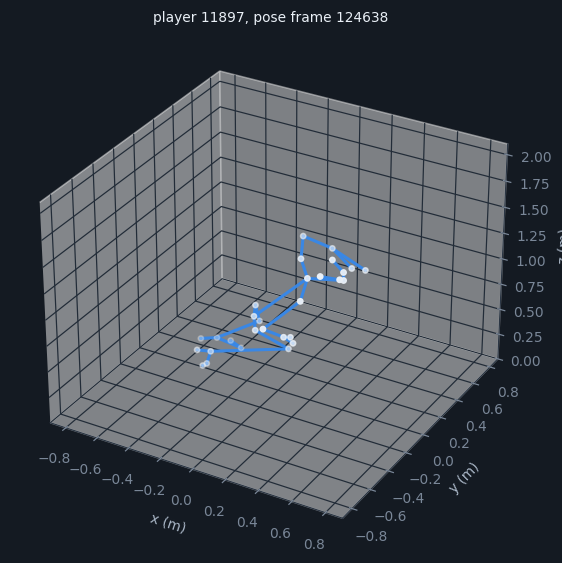

In [3]:
f = orient.pose_frame.iloc[len(orient) // 2]
pid = orient[orient.pose_frame == f].player_id.iloc[0]
jf = joints[(joints.pose_frame == f) & (joints.player_id == pid)].set_index("joint")
fig = plt.figure(figsize=(5, 5.4)); ax = fig.add_subplot(111, projection="3d")
ox, oy = jf.jx.mean(), jf.jy.mean()
for a, b in SKELETON:
    if a in jf.index and b in jf.index:
        ax.plot([jf.loc[a, "jx"] - ox, jf.loc[b, "jx"] - ox],
                [jf.loc[a, "jy"] - oy, jf.loc[b, "jy"] - oy],
                [jf.loc[a, "jz"], jf.loc[b, "jz"]], color=PALETTE["accent"], lw=2)
ax.scatter(jf.jx - ox, jf.jy - oy, jf.jz, s=12, color=PALETTE["text"])
ax.set_xlim(-0.9, 0.9); ax.set_ylim(-0.9, 0.9); ax.set_zlim(0, 2.1)
ax.set_xlabel("x (m)"); ax.set_ylabel("y (m)"); ax.set_zlabel("z (m)")
ax.set_title(f"player {pid}, pose frame {f}", fontsize=9); plt.tight_layout()

## Does the orientation construction hold up?

The facing vector is the shoulder line rotated 90 degrees. If the sign were
inverted the check below would sit near 180 degrees instead of near 9.

In [4]:
from src.preprocessing.build_tracking import load_tracking
o = orient[orient.orientation_valid].copy()
o["frame"] = o.tracking_frame.round().astype(int)
trk = load_tracking(int(o.match_id.iloc[0]), columns=["frame", "player_id", "heading", "speed"])
m = o.merge(trk, on=["frame", "player_id"])
m["abs_diff_deg"] = np.degrees(np.abs(np.arctan2(np.sin(m.facing_rad - m.heading),
                                                 np.cos(m.facing_rad - m.heading))))
m["band"] = pd.cut(m.speed, [0, 1, 2, 4, 20], labels=["<1", "1-2", "2-4", ">4"])
m.groupby("band", observed=True).agg(
    n=("abs_diff_deg", "size"), median_deg=("abs_diff_deg", "median"),
    within_45=("abs_diff_deg", lambda s: (s < 45).mean())).round(2)

,n,median_deg,within_45
band,,,
<1,545,68.66,0.29
1-2,1115,25.08,0.69
2-4,2294,13.13,0.85
>4,999,9.04,0.95


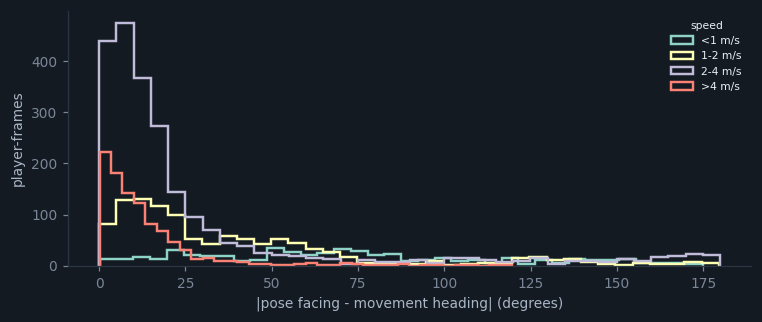

In [5]:
fig, ax = plt.subplots(figsize=(7, 3))
for band, sub in m.groupby("band", observed=True):
    ax.hist(sub.abs_diff_deg, bins=36, histtype="step", lw=1.6, label=f"{band} m/s")
ax.set_xlabel("|pose facing - movement heading| (degrees)"); ax.set_ylabel("player-frames")
ax.legend(frameon=False, title="speed", title_fontsize=7, fontsize=7)
ax.spines[["top", "right"]].set_visible(False); plt.tight_layout()

The agreement is monotone in speed: 9 degrees above 4 m/s, 69 degrees below
1 m/s. That is exactly the expected pattern -- a standing player has no
meaningful movement heading -- and it is what licenses using heading as a
proxy for orientation across all 20 matches, restricted to moving receivers.

## Orientation in this phase

In [6]:
orient.groupby("body_orientation_class", observed=True).agg(
    frames=("openness", "size"), mean_openness=("openness", "mean"),
    trunk_lean_deg=("trunk_lean_deg", "mean"),
    shoulder_hip_twist_deg=("shoulder_hip_twist_deg", "mean")).round(2)

,frames,mean_openness,trunk_lean_deg,shoulder_hip_twist_deg
body_orientation_class,,,,
forward,2081,0.84,11.62,13.10
sideways,984,-0.01,13.46,9.95
backward,1888,-0.83,11.90,16.22


n is one 12.3-second phase of play. This is a demonstration of the measurement, not a positional norm.